In [2]:
# pip install kagglehub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [4]:
import os
print(os.listdir(path))

['plantvillage dataset']


In [5]:
import os
dataset_path = os.path.join(path, 'plantvillage dataset')

print(os.listdir(dataset_path))

['segmented', 'grayscale', 'color']


In [6]:
data_dir = os.path.join(dataset_path, 'color')
print(os.listdir(data_dir))

['Tomato___Late_blight', 'Tomato___healthy', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Potato___healthy', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Early_blight', 'Tomato___Septoria_leaf_spot', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Strawberry___Leaf_scorch', 'Peach___healthy', 'Apple___Apple_scab', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Bacterial_spot', 'Apple___Black_rot', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Peach___Bacterial_spot', 'Apple___Cedar_apple_rust', 'Tomato___Target_Spot', 'Pepper,_bell___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Potato___Late_blight', 'Tomato___Tomato_mosaic_virus', 'Strawberry___healthy', 'Apple___healthy', 'Grape___Black_rot', 'Potato___Early_blight', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Common_rust_', 'Grape___Esca_(Black_Measles)', 'Raspberry___healthy', 'Tomato___Leaf_Mold', 'Tomato__

In [7]:
classes = os.listdir(data_dir)
num_classes = len(classes)
print("Total number of classes:", num_classes)

Total number of classes: 38


### Observation – Dataset Structure
The PlantVillage dataset contains 38 different classes, representing various plant species and their corresponding disease conditions.
- Each class is stored in a separate folder.
- The dataset includes both healthy and diseased plant leaf images.
- It covers multiple crops, including Apple, Tomato, Potato, Grape, Corn and others.
- The dataset is organized according to plant type and disease category.

In [8]:
class_counts = {}

for class_name in classes:
    class_path = os.path.join(data_dir, class_name)
    images = os.listdir(class_path)
    class_counts[class_name] = len(images)

for class_name, count in class_counts.items():
    print(class_name, ":", count)

Tomato___Late_blight : 1909
Tomato___healthy : 1591
Grape___healthy : 423
Orange___Haunglongbing_(Citrus_greening) : 5507
Soybean___healthy : 5090
Squash___Powdery_mildew : 1835
Potato___healthy : 152
Corn_(maize)___Northern_Leaf_Blight : 985
Tomato___Early_blight : 1000
Tomato___Septoria_leaf_spot : 1771
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513
Strawberry___Leaf_scorch : 1109
Peach___healthy : 360
Apple___Apple_scab : 630
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 5357
Tomato___Bacterial_spot : 2127
Apple___Black_rot : 621
Blueberry___healthy : 1502
Cherry_(including_sour)___Powdery_mildew : 1052
Peach___Bacterial_spot : 2297
Apple___Cedar_apple_rust : 275
Tomato___Target_Spot : 1404
Pepper,_bell___healthy : 1478
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
Potato___Late_blight : 1000
Tomato___Tomato_mosaic_virus : 373
Strawberry___healthy : 456
Apple___healthy : 1645
Grape___Black_rot : 1180
Potato___Early_blight : 1000
Cherry_(including_sour)___healthy : 854
Corn_

The number of images varies considerably across the 38 classes.
- Highest image count: Orange – Haunglongbing (Citrus greening), with 5,507 images.
- Lowest image count: Potato – Healthy, with 152 images.
- Some classes contain more than 5,000 images, while others contain fewer than 500 images.

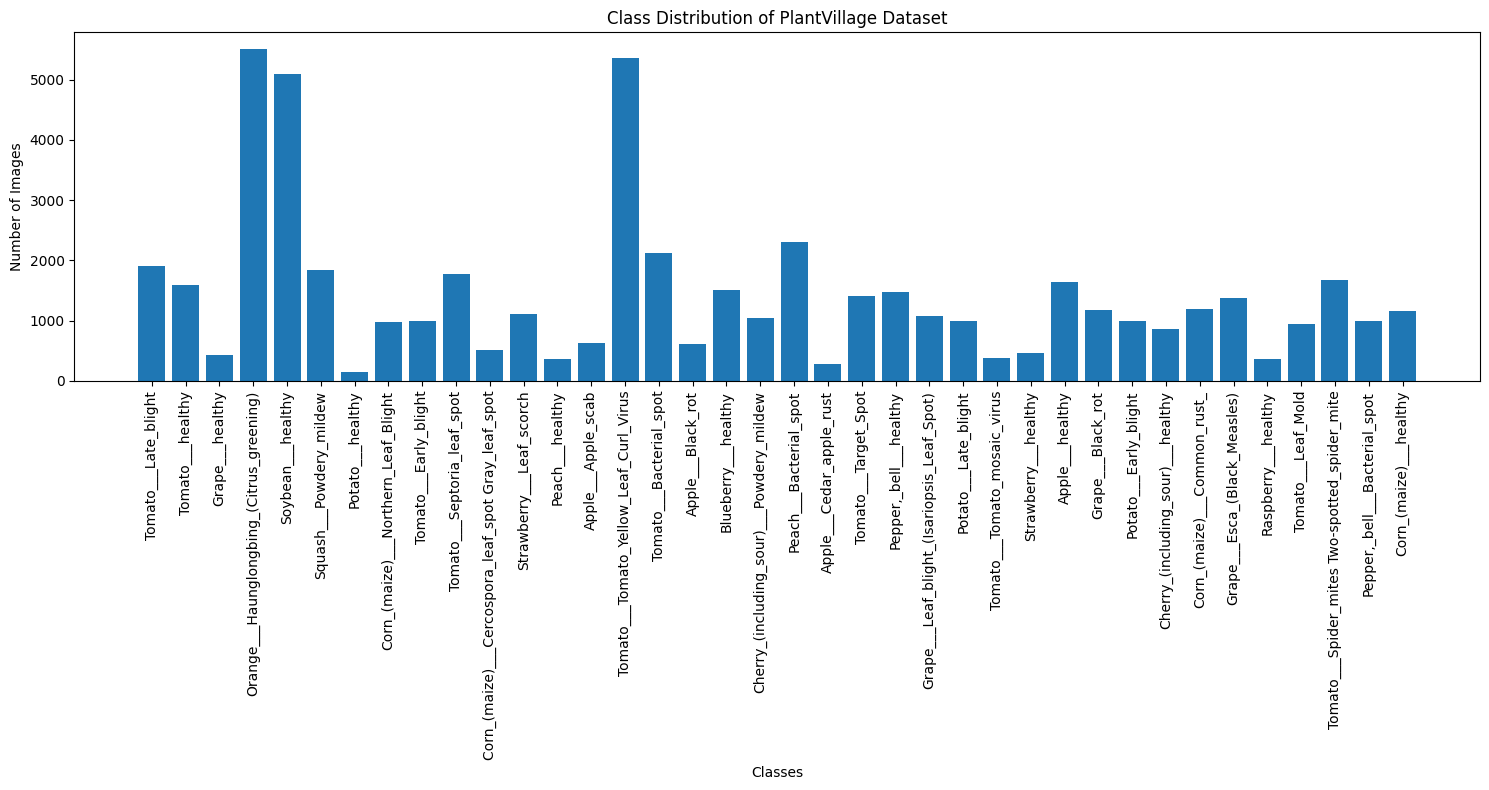

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Class Distribution of PlantVillage Dataset")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Conclusion: The dataset is imbalanced, so class distribution should be considered during model training and evaluation.

In [10]:
from PIL import Image

image_dimensions = []

for class_name in classes:
    class_path = os.path.join(data_dir, class_name)

    for image_name in os.listdir(class_path):
        image_path = os.path.join(class_path, image_name)

        img = Image.open(image_path)
        image_dimensions.append(img.size)

print("Total images:", len(image_dimensions))
print("First 10 image dimensions:", image_dimensions[:10])

Total images: 54305
First 10 image dimensions: [(256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256), (256, 256)]


* Total number of images: 54,305.
* The first 10 images have dimensions of 256 × 256 pixels.

In [11]:
unique_dimensions = set(image_dimensions)

print("Unique image dimensions:", unique_dimensions)
print("Number of unique dimensions:", len(unique_dimensions))

Unique image dimensions: {(256, 256)}
Number of unique dimensions: 1


In [12]:
img = Image.open(image_path)

print("Image mode:", img.mode)
print("Image size:", img.size)

Image mode: RGB
Image size: (256, 256)


In [13]:
corrupted_images = []

for class_name in classes:
    class_path = os.path.join(data_dir, class_name)

    for image_name in os.listdir(class_path):
        image_path = os.path.join(class_path, image_name)

        try:
            img = Image.open(image_path)
            img.verify()

        except:
            corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


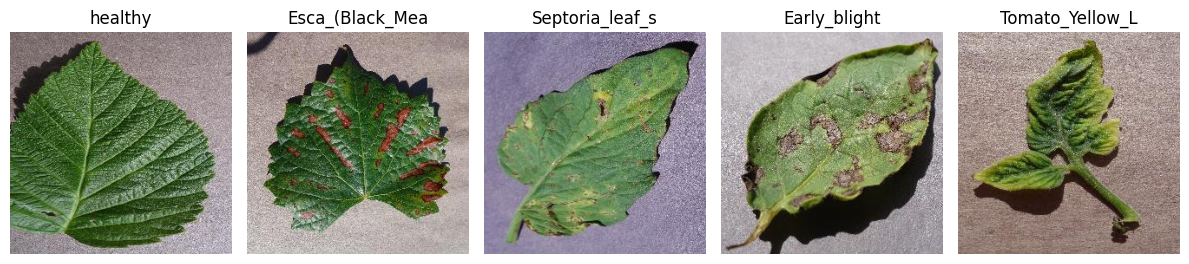

In [14]:
import random

plt.figure(figsize=(12, 6))

for i in range(5):
    class_name = random.choice(classes)
    class_path = os.path.join(data_dir, class_name)
    image_name = random.choice(os.listdir(class_path))

    image_path = os.path.join(class_path, image_name)
    img = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(class_name.split("___")[1][:15])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# pip install albumentations

In [15]:
import albumentations as A

transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=20, p=0.5),
    A.RandomBrightnessContrast(p=0.5)
])

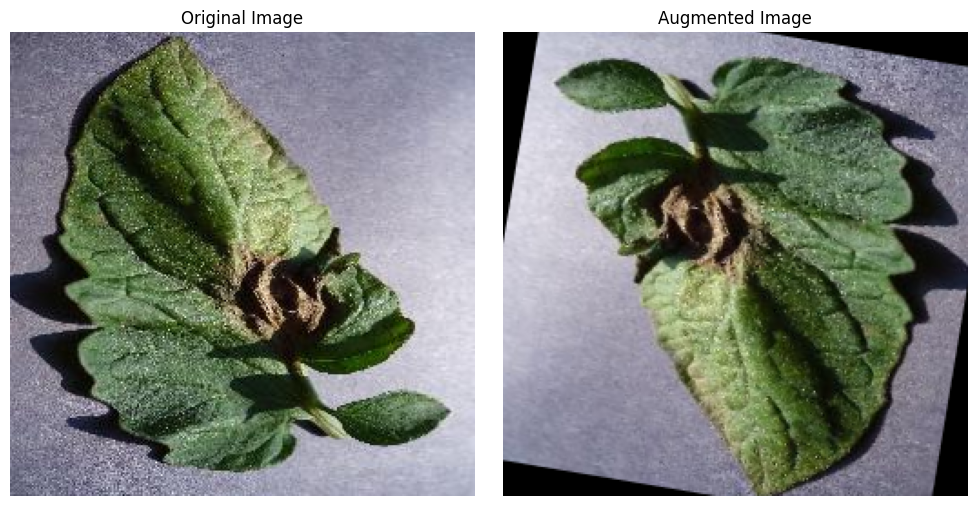

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select a sample image
sample_image_path = os.path.join(
    data_dir,
    classes[0],
    os.listdir(os.path.join(data_dir, classes[0]))[0]
)

# Read the original image
original_image = np.array(Image.open(sample_image_path))

# Apply augmentation
augmented_image = transform(image=original_image)['image']

# Display both images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
import tensorflow as tf

IMG_SIZE = (256, 256)
BATCH_SIZE = 32

print("TensorFlow Version:", tf.__version__)
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)

TensorFlow Version: 2.21.0
Image Size: (256, 256)
Batch Size: 32


In [18]:
from sklearn.model_selection import train_test_split

image_paths = []
labels = []

for class_name in classes:
    class_path = os.path.join(data_dir, class_name)

    for image_name in os.listdir(class_path):
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))

Total images: 54305
Total labels: 54305


In [19]:
# First split: 80% training and 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Second split: Divide remaining 20% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 43444
Validation images: 5430
Testing images: 5431


In [20]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Number of classes:", len(label_encoder.classes_))
print("Encoded training labels:", y_train_encoded[:10])

Number of classes: 38
Encoded training labels: [28 24  9 25  4 28 24 35 33 24]


In [21]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    return image, label

In [22]:
def load_and_augment_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.uint8)

    image = tf.numpy_function(
        lambda img: transform(image=img)['image'],
        [image],
        tf.uint8
    )

    image.set_shape((256, 256, 3))
    image = tf.cast(image, tf.float32)

    return image, label

In [23]:
AUTOTUNE = tf.data.AUTOTUNE

# Training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train_encoded)
)

train_ds = train_ds.map(
    load_and_augment_image,
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.map(
    lambda x, y: (x, tf.one_hot(y, depth=38))
)

train_ds = train_ds.shuffle(1000)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Validation dataset
val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val_encoded)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (x, tf.one_hot(y, depth=38))
)

val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Testing dataset
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_encoded)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (x, tf.one_hot(y, depth=38))
)

test_ds = test_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("All datasets created successfully!")

All datasets created successfully!


In [24]:
for images, labels in train_ds.take(1):
    print("Training:", images.shape, labels.shape)

for images, labels in val_ds.take(1):
    print("Validation:", images.shape, labels.shape)

for images, labels in test_ds.take(1):
    print("Testing:", images.shape, labels.shape)

Training: (32, 256, 256, 3) (32, 38)
Validation: (32, 256, 256, 3) (32, 38)
Testing: (32, 256, 256, 3) (32, 38)


In [25]:
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Keras location:", keras.__file__)

TensorFlow version: 2.21.0
Keras version: 3.13.2
Keras location: /usr/local/lib/python3.13/dist-packages/keras/__init__.py


In [26]:
print("KerasTensor available:", hasattr(keras, 'KerasTensor'))

print("TensorFlow Keras:", tf.keras)

print("Keras backend:", keras.backend.backend())

KerasTensor available: True
TensorFlow Keras: <KerasLazyLoader>
Keras backend: tensorflow


In [27]:
import tensorflow as tf
import keras

from tensorflow.keras.applications import EfficientNetB0, MobileNetV2

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)

print("EfficientNetB0 loaded successfully!")

TensorFlow: 2.21.0
Keras: 3.13.2
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully!


In [28]:
mobilenet_base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)

print("MobileNetV2 loaded successfully!")

/tmp/ipykernel_12220/729127496.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [29]:
efficientnet_base.trainable = False
mobilenet_base.trainable = False

print("EfficientNetB0 trainable:", efficientnet_base.trainable)
print("MobileNetV2 trainable:", mobilenet_base.trainable)

EfficientNetB0 trainable: False
MobileNetV2 trainable: False


EfficientNetB0 and MobileNetV2 were selected as the two pretrained CNN architectures for plant disease classification. Both models were loaded using ImageNet pretrained weights with their original classification heads removed. Their pretrained layers were frozen to preserve the learned features during the initial training stage.

In [30]:
from tensorflow.keras import layers, models

efficientnet_model = models.Sequential([
    efficientnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(38, activation='softmax')
])

print("EfficientNetB0 classification head created!")

EfficientNetB0 classification head created!


In [31]:
mobilenet_model = models.Sequential([
    layers.Rescaling(1./127.5, offset=-1),
    mobilenet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(38, activation='softmax')
])

print("MobileNetV2 classification head created!")

MobileNetV2 classification head created!


Custom classification heads were added to EfficientNetB0 and MobileNetV2. Global Average Pooling was used for feature reduction, Dropout layers were added to reduce overfitting, and a final Softmax layer was designed to classify images into 38 plant disease categories.

In [32]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First label:", labels[0].numpy())

Image batch shape: (32, 256, 256, 3)
Label batch shape: (32, 38)
First label: [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [33]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.1
    ),
    metrics=['accuracy']
)

print("EfficientNetB0 compiled successfully!")

EfficientNetB0 compiled successfully!


In [34]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.1
    ),
    metrics=['accuracy']
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [35]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

def create_callbacks(model_name):
    return [
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.2,
            patience=3,
            min_lr=0.00001
        ),

        ModelCheckpoint(
            f'best_{model_name}.keras',
            monitor='val_loss',
            save_best_only=True
        )
    ]

In [36]:
history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=create_callbacks("efficientnet")
)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 175s 104ms/step - accuracy: 0.8511 - loss: 1.2145 - val_accuracy: 0.9516 - val_loss: 0.8975 - learning_rate: 0.0010
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 112s 81ms/step - accuracy: 0.9215 - loss: 1.0113 - val_accuracy: 0.9619 - val_loss: 0.8680 - learning_rate: 0.0010
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 110s 80ms/step - accuracy: 0.9314 - loss: 0.9796 - val_accuracy: 0.9674 - val_loss: 0.8472 - learning_rate: 0.0010
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 111s 80ms/step - accuracy: 0.9377 - loss: 0.9642 - val_accuracy: 0.9718 - val_loss: 0.8378 - learning_rate: 0.0010
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 112s 81ms/step - accuracy: 0.9432 - loss: 0.9505 - val_accuracy: 0.9707 - val_loss: 0.8355 - learning_rate: 0.0010
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 112s 81ms/step - accuracy: 0.9444 - loss: 0.9412 - val_accuracy: 0.9751 - val_loss: 0.8200 - learning_rate: 0.0010
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 111s 80ms/step 

In [37]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=create_callbacks("mobilenet")
)

Epoch 1/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 132s 88ms/step - accuracy: 0.8079 - loss: 1.3382 - val_accuracy: 0.9304 - val_loss: 0.9838 - learning_rate: 0.0010
Epoch 2/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 111s 80ms/step - accuracy: 0.8855 - loss: 1.1270 - val_accuracy: 0.9320 - val_loss: 0.9505 - learning_rate: 0.0010
Epoch 3/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 144s 81ms/step - accuracy: 0.8965 - loss: 1.0910 - val_accuracy: 0.9429 - val_loss: 0.9296 - learning_rate: 0.0010
Epoch 4/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 109s 79ms/step - accuracy: 0.9027 - loss: 1.0673 - val_accuracy: 0.9424 - val_loss: 0.9165 - learning_rate: 0.0010
Epoch 5/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 104s 76ms/step - accuracy: 0.9092 - loss: 1.0525 - val_accuracy: 0.9492 - val_loss: 0.8995 - learning_rate: 0.0010
Epoch 6/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 107s 78ms/step - accuracy: 0.9104 - loss: 1.0423 - val_accuracy: 0.9484 - val_loss: 0.8970 - learning_rate: 0.0010
Epoch 7/10
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 106s 77ms/step -

In [38]:
# Save EfficientNetB0
efficientnet_model.save("efficientnet_plant_disease.keras")

# Save MobileNetV2
mobilenet_model.save("mobilenet_plant_disease.keras")

print("Both models saved successfully!")

Both models saved successfully!


In [39]:
import tensorflow as tf

efficientnet_model = tf.keras.models.load_model(
    "efficientnet_plant_disease.keras"
)

mobilenet_model = tf.keras.models.load_model(
    "mobilenet_plant_disease.keras"
)

print("Both models loaded successfully!")

Both models loaded successfully!


In [40]:
efficientnet_results = efficientnet_model.evaluate(test_ds)
mobilenet_results = mobilenet_model.evaluate(test_ds)

print("\nEfficientNetB0")
print("Test Loss:", efficientnet_results[0])
print("Test Accuracy:", efficientnet_results[1])

print("\nMobileNetV2")
print("Test Loss:", mobilenet_results[0])
print("Test Accuracy:", mobilenet_results[1])

170/170 ━━━━━━━━━━━━━━━━━━━━ 27s 104ms/step - accuracy: 0.9809 - loss: 0.8023
170/170 ━━━━━━━━━━━━━━━━━━━━ 15s 65ms/step - accuracy: 0.9602 - loss: 0.8709

EfficientNetB0
Test Loss: 0.8022883534431458
Test Accuracy: 0.9808506965637207

MobileNetV2
Test Loss: 0.8708703517913818
Test Accuracy: 0.9602283239364624


In [41]:
import numpy as np
from sklearn.metrics import classification_report

# Get actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds
])

# Get EfficientNet predictions
y_pred_eff = np.argmax(
    efficientnet_model.predict(test_ds),
    axis=1
)

# Get MobileNet predictions
y_pred_mob = np.argmax(
    mobilenet_model.predict(test_ds),
    axis=1
)

# Class names
class_names = label_encoder.classes_

print("EFFICIENTNETB0 CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_eff,
    target_names=class_names
))

print("\nMOBILENETV2 CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_mob,
    target_names=class_names
))

170/170 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step
170/170 ━━━━━━━━━━━━━━━━━━━━ 15s 66ms/step
EFFICIENTNETB0 CLASSIFICATION REPORT
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        63
                                 Apple___Black_rot       1.00      0.98      0.99        62
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        27
                                   Apple___healthy       0.99      1.00      1.00       165
                               Blueberry___healthy       0.99      1.00      0.99       150
          Cherry_(including_sour)___Powdery_mildew       1.00      0.99      1.00       105
                 Cherry_(including_sour)___healthy       1.00      0.99      0.99        85
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.82      0.87        51
                       Corn_(maize)___Common_rus

EfficientNetB0 performs consistently better across the overall metrics.



Both models perform well on most plant disease classes.



Potato___healthy is a challenging class, especially for MobileNetV2, with recall of only 0.47.



Tomato___Early_blight is another challenging class for both models.



Some classes have very small test support, such as Potato healthy (15 images), so their scores should be interpreted cautiously.

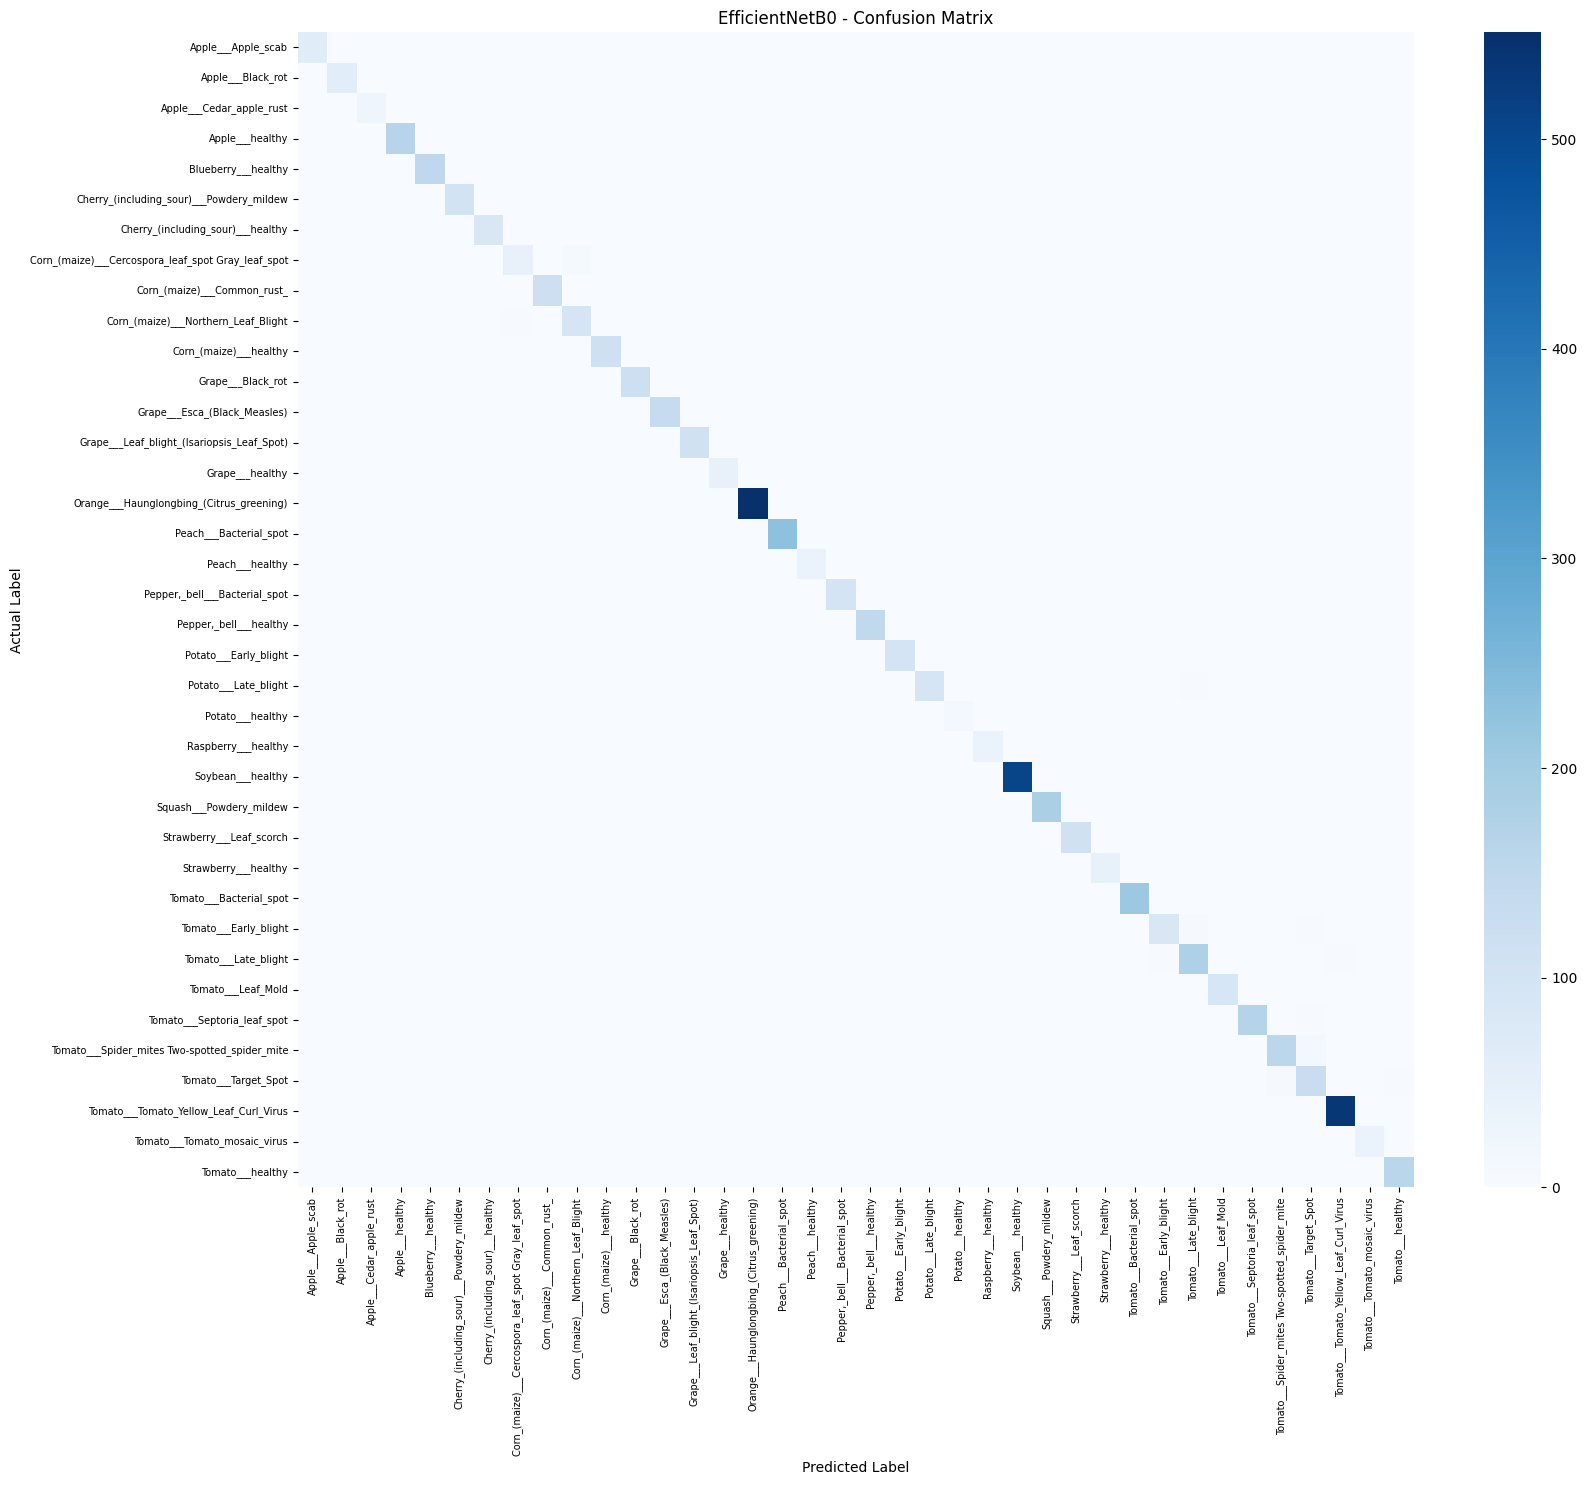

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# EfficientNetB0 confusion matrix
cm_eff = confusion_matrix(y_true, y_pred_eff)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm_eff,
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.show()

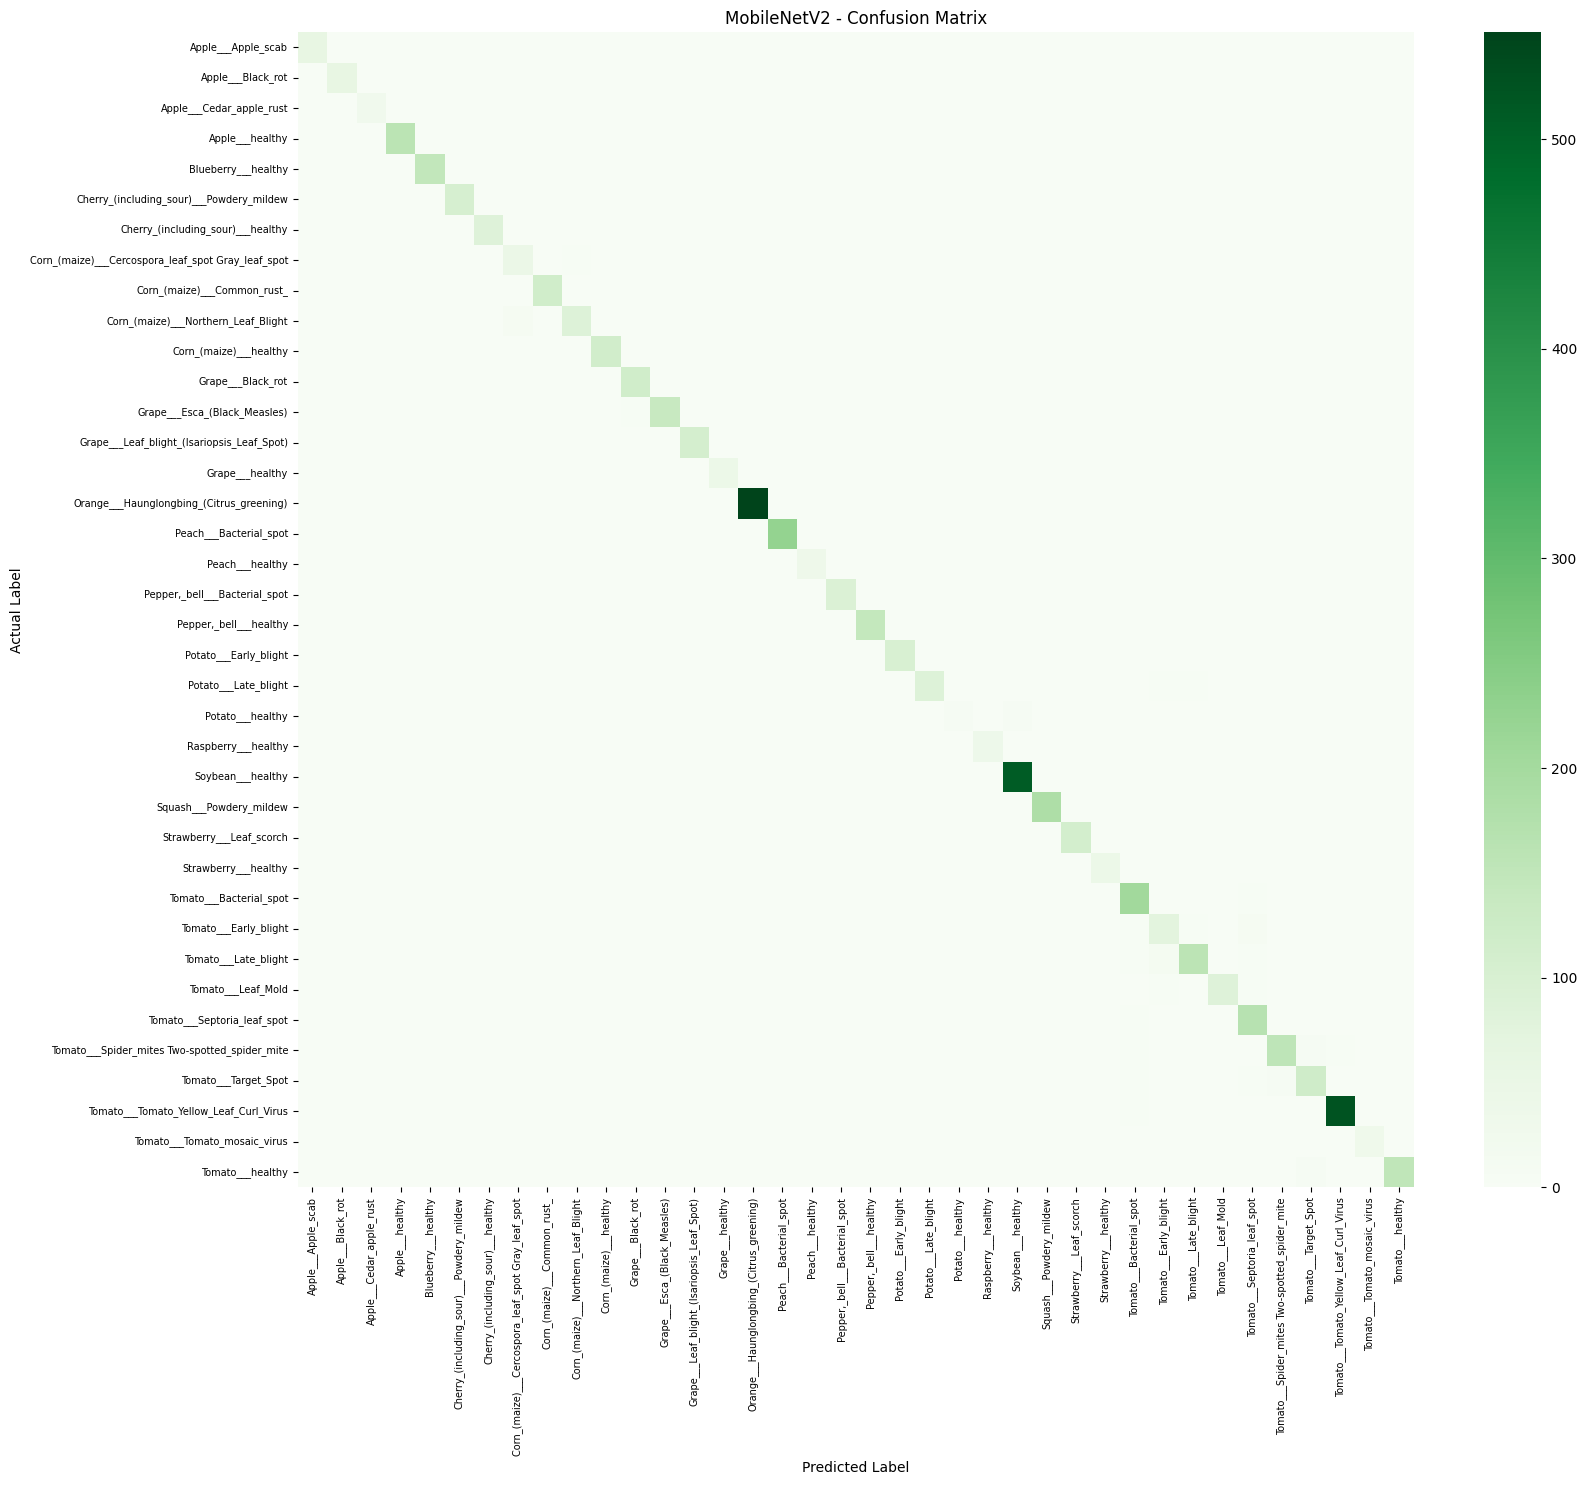

In [43]:
cm_mob = confusion_matrix(y_true, y_pred_mob)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm_mob,
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.show()

EfficientNetB0 demonstrates better classification performance than MobileNetV2.

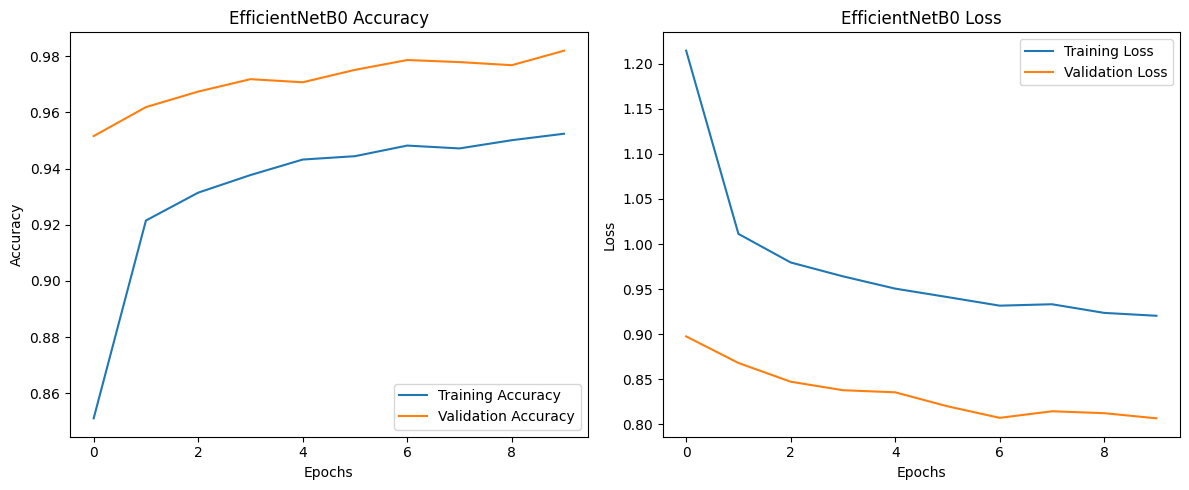

In [44]:
import matplotlib.pyplot as plt

# EfficientNetB0 Learning Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_efficientnet.history['accuracy'], label='Training Accuracy')
plt.plot(history_efficientnet.history['val_accuracy'], label='Validation Accuracy')
plt.title('EfficientNetB0 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnet.history['loss'], label='Training Loss')
plt.plot(history_efficientnet.history['val_loss'], label='Validation Loss')
plt.title('EfficientNetB0 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

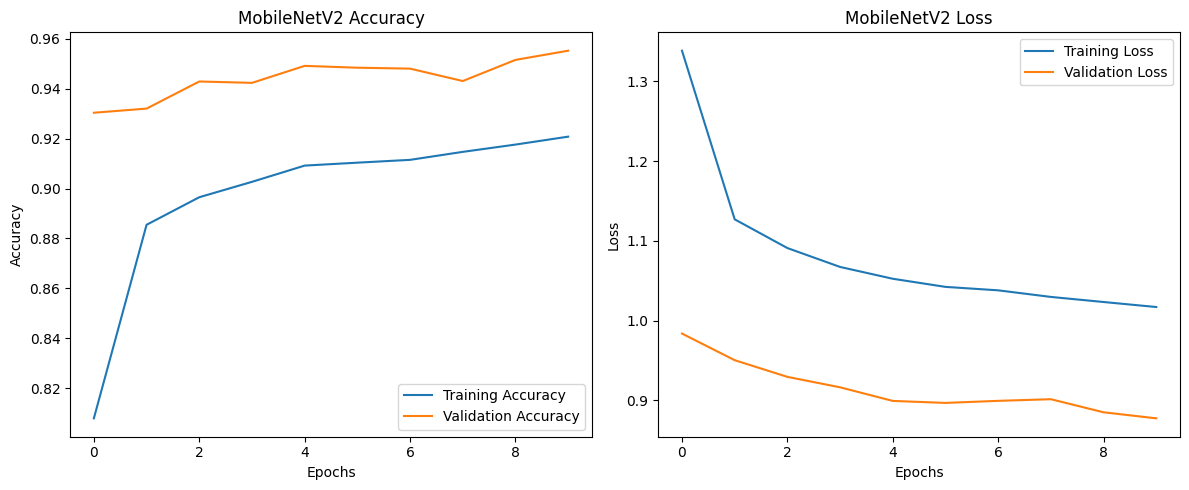

In [45]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history['accuracy'], label='Training Accuracy')
plt.plot(history_mobilenet.history['val_accuracy'], label='Validation Accuracy')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history['loss'], label='Training Loss')
plt.plot(history_mobilenet.history['val_loss'], label='Validation Loss')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Total test images: 5431
Incorrect predictions: 104
Correct predictions: 5327


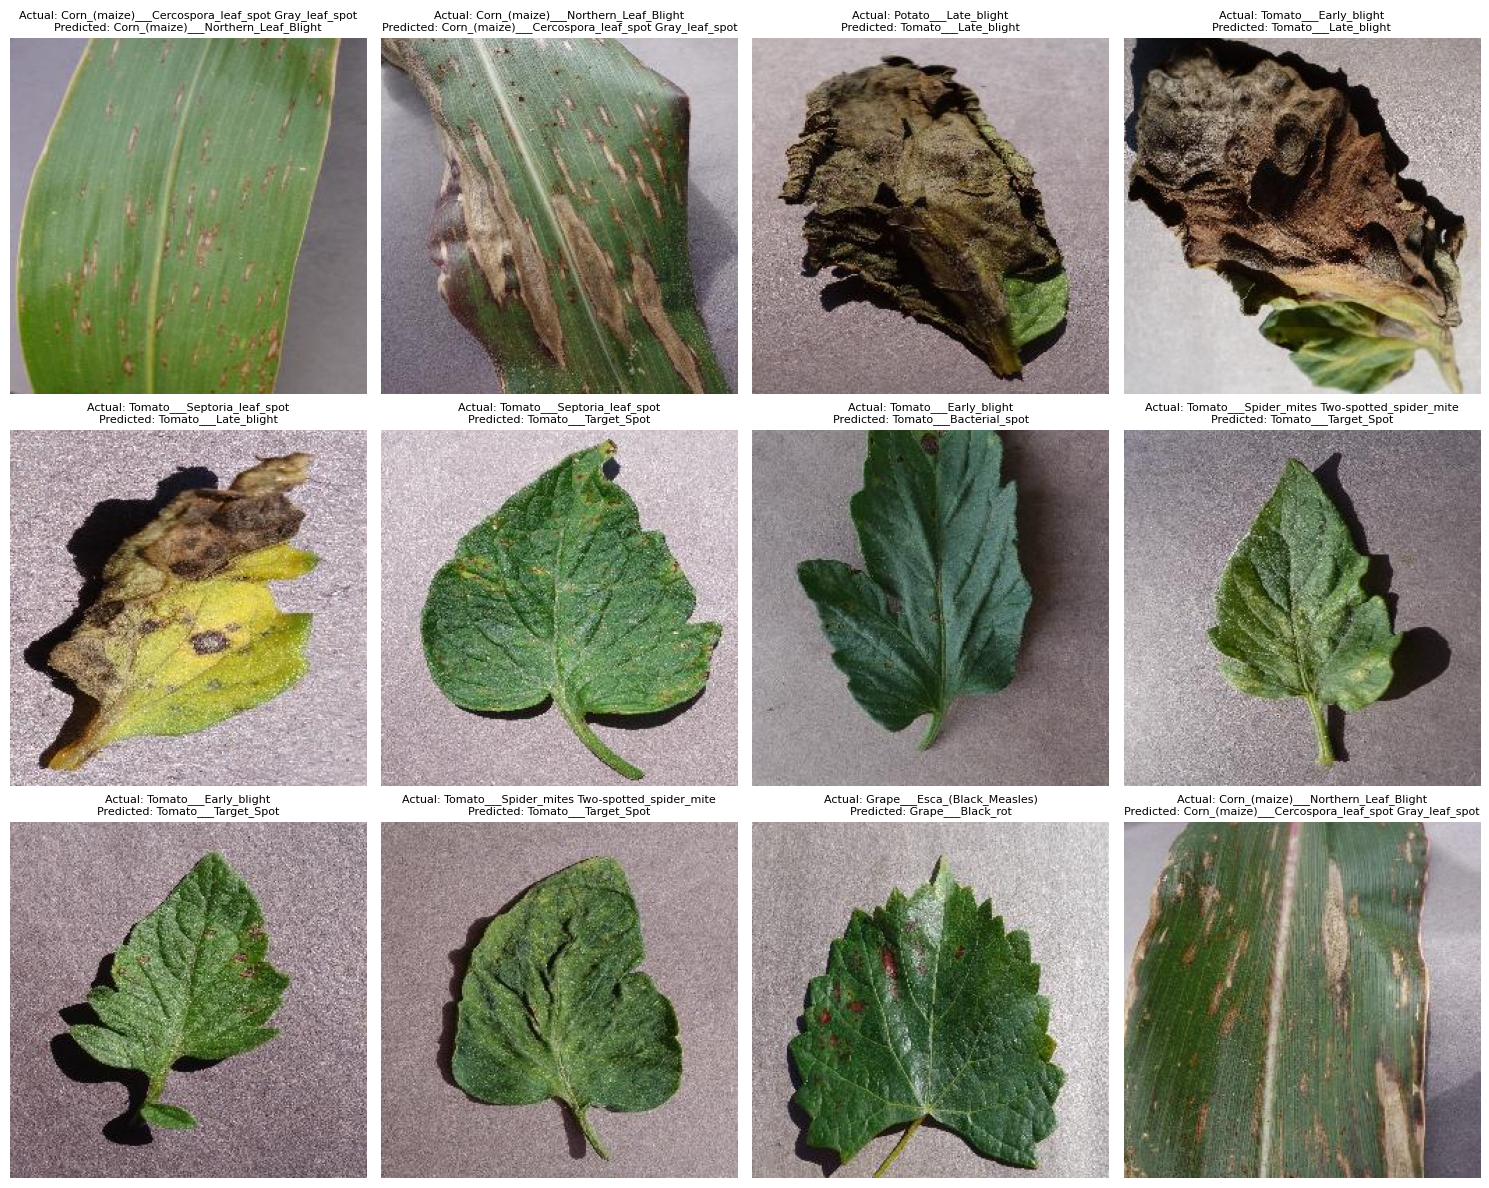

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Find incorrectly classified test images
misclassified_indices = np.where(y_true != y_pred_eff)[0]

print("Total test images:", len(y_true))
print("Incorrect predictions:", len(misclassified_indices))
print("Correct predictions:", len(y_true) - len(misclassified_indices))

# Display first 12 misclassified images
plt.figure(figsize=(15, 12))

for i, idx in enumerate(misclassified_indices[:12]):
    image_path = X_test[idx]
    image = Image.open(image_path).convert("RGB")

    actual = class_names[y_true[idx]]
    predicted = class_names[y_pred_eff[idx]]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [47]:
import pandas as pd
import numpy as np

# Copy confusion matrix
cm = confusion_matrix(y_true, y_pred_eff)

# Remove correct predictions (diagonal)
np.fill_diagonal(cm, 0)

# Find the most frequent incorrect predictions
error_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm[i, j] > 0:
            error_pairs.append({
                'Actual Disease': class_names[i],
                'Predicted Disease': class_names[j],
                'Number of Errors': cm[i, j]
            })

error_df = pd.DataFrame(error_pairs)

error_df = error_df.sort_values(
    by='Number of Errors',
    ascending=False
)

print("Top 10 Most Confused Disease Classes:")
display(error_df.head(10))

Top 10 Most Confused Disease Classes:


,Actual Disease,Predicted Disease,Number of Errors
42,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,12
3,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,9
21,Tomato___Early_blight,Tomato___Late_blight,8
44,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,7
40,Tomato___Septoria_leaf_spot,Tomato___Target_Spot,4
4,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,4
12,Potato___Late_blight,Tomato___Late_blight,3
30,Tomato___Late_blight,Tomato___Tomato_Yellow_Leaf_Curl_Virus,3
23,Tomato___Early_blight,Tomato___Target_Spot,3
46,Tomato___Target_Spot,Tomato___healthy,3


### Error Analysis

The EfficientNetB0 model achieved 98.09% test accuracy, correctly classifying 5,327 out of 5,431 test images. Only 104 images were incorrectly classified.

The error analysis revealed that certain plant disease classes were more frequently confused with one another. The most common confusion occurred between Tomato Spider Mites and Tomato Target Spot, with 12 misclassified images. Other frequent errors involved Corn Cercospora Leaf Spot and Northern Leaf Blight, as well as Tomato Early Blight and Late Blight.

Possible reasons for these errors include:

- Similar visual symptoms among different plant diseases.
- Overlapping patterns of leaf spots, discoloration and lesions.
- Variations in image lighting, shadows and background.
- Limited training samples for certain disease classes.

### Model Limitations

- The model is trained using the PlantVillage dataset and may not generalize equally well to all real-world field conditions.
- Similar disease symptoms can lead to incorrect predictions.
- Image quality, lighting and background variations may affect prediction performance.
- Some disease classes have fewer samples than others, which may affect classification reliability.
- The model predicts from visual patterns and does not replace expert agricultural diagnosis.

In [48]:
import os
import time
import numpy as np

# Original model size
model_path = "efficientnet_plant_disease.keras"

model_size = os.path.getsize(model_path) / (1024 * 1024)

# Get one batch of test images
for images, labels in test_ds.take(1):
    sample_images = images[:1]

# Warm-up prediction
efficientnet_model(sample_images, training=False)

# Measure inference time
start_time = time.time()

for _ in range(100):
    efficientnet_model(sample_images, training=False)

end_time = time.time()

avg_time = (end_time - start_time) / 100

print("Original EfficientNetB0")
print("Model Size:", round(model_size, 2), "MB")
print("Average Inference Time:", round(avg_time * 1000, 2), "ms")

Original EfficientNetB0
Model Size: 20.12 MB
Average Inference Time: 333.25 ms


In [49]:
import tensorflow as tf

# Create TFLite converter
converter = tf.lite.TFLiteConverter.from_keras_model(
    efficientnet_model
)

# Apply dynamic range quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Convert model
quantized_model = converter.convert()

# Save optimized model
with open("efficientnet_plant_disease_quantized.tflite", "wb") as f:
    f.write(quantized_model)

print("Quantized model saved successfully!")

Saved artifact at '/tmp/tmpvx25xjr_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  137611319468368: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  137611319468176: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  137611828107536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828110224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828109648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828110800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828106960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828110416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828111184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137611828110992: TensorSpec(shape=(), dtype=tf.resource, name=No

In [50]:
import os

quantized_size = os.path.getsize(
    "efficientnet_plant_disease_quantized.tflite"
) / (1024 * 1024)

print("Original Model Size:", round(model_size, 2), "MB")
print("Quantized Model Size:", round(quantized_size, 2), "MB")

reduction = ((model_size - quantized_size) / model_size) * 100

print("Size Reduction:", round(reduction, 2), "%")

Original Model Size: 20.12 MB
Quantized Model Size: 4.68 MB
Size Reduction: 76.73 %


In [51]:
# Load quantized TFLite model
interpreter = tf.lite.Interpreter(
    model_path="efficientnet_plant_disease_quantized.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Get one test image
sample_image = sample_images.numpy()

# Run prediction
interpreter.set_tensor(
    input_details[0]['index'],
    sample_image
)

interpreter.invoke()

prediction = interpreter.get_tensor(
    output_details[0]['index']
)

predicted_class = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

print("Predicted Disease:", label_encoder.classes_[predicted_class])
print("Confidence:", round(confidence, 2), "%")

Predicted Disease: Apple___Black_rot
Confidence: 81.75 %


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [53]:
y_pred_quantized = []

for images, labels in test_ds:
    batch_images = images.numpy()

    # Resize interpreter input to match the current batch
    interpreter.resize_tensor_input(
        input_details[0]['index'],
        batch_images.shape
    )
    interpreter.allocate_tensors()

    # Refresh tensor details after resizing
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    interpreter.set_tensor(
        input_details[0]['index'],
        batch_images
    )

    interpreter.invoke()

    predictions = interpreter.get_tensor(
        output_details[0]['index']
    )

    predicted_labels = np.argmax(predictions, axis=1)
    y_pred_quantized.extend(predicted_labels)

y_pred_quantized = np.array(y_pred_quantized)

from sklearn.metrics import accuracy_score

quantized_accuracy = accuracy_score(y_true, y_pred_quantized)

print("Quantized Model Accuracy:", round(quantized_accuracy * 100, 2), "%")

Quantized Model Accuracy: 98.01 %


In [54]:
import time

# Get one test image
for images, labels in test_ds.take(1):
    sample_image = images[:1].numpy()

# Refresh interpreter details
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Resize input to one image
interpreter.resize_tensor_input(
    input_details[0]['index'],
    sample_image.shape
)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Warm-up
for _ in range(5):
    interpreter.set_tensor(input_details[0]['index'], sample_image)
    interpreter.invoke()

# Measure inference time
start_time = time.time()

for _ in range(100):
    interpreter.set_tensor(input_details[0]['index'], sample_image)
    interpreter.invoke()

end_time = time.time()

avg_time = (end_time - start_time) / 100 * 1000

print("Quantized Model Average Inference Time:", round(avg_time, 2), "ms")

Quantized Model Average Inference Time: 86.39 ms


Optimization using TensorFlow Lite Dynamic Range Quantization

Dynamic range quantization was applied to the best-performing EfficientNetB0 model. It reduces the size of the model by quantizing its weights while keeping the input and output in floating-point format.

The quantized model achieved 98.01% test accuracy compared with 98.09% for the original model. Its size decreased from 20.12 MB to 4.68 MB, and average single-image inference time decreased from 333.25 ms to 86.39 ms. Therefore, quantization improved model efficiency with only a negligible accuracy reduction.

In [55]:
import json

class_names = label_encoder.classes_.tolist()

with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")
print("Number of classes:", len(class_names))

Class names saved successfully!
Number of classes: 38
